# Module 2 Lab — Full Techniques Walkthrough

Companion notebook to **all four Module 2 study guides**, run end-to-end on one small local model — no API key required:

| Part | Study guide | Techniques demonstrated |
|---|---|---|
| 1 | `1_Prompt_Engineering.html` | Zero-shot, few-shot, chain-of-thought, self-consistency |
| 2 | `2_Advanced_Reasoning.html` | Tree-of-Thoughts, Graph-of-Thoughts, PAL/PoT, **ReAct (with real grounding)**, reflection, self-critique |
| 3 | `3_Test_Time_Scaling.html` | Deliberate reasoning, majority voting at scale, self-reflection as compute allocation, an actual inference-compute scaling curve |
| 4 | `4_Structured_Generation.html` | JSON outputs (`outlines`), function/tool calling, **LangChain**, **DSPy** prompt optimization |

**Model**: `Qwen/Qwen2.5-0.5B-Instruct` — small enough for CPU/Apple-Silicon MPS, and (unlike encoder-decoder models such as FLAN-T5) a real chat-template-aware instruct model, which DSPy's structured prompting, `outlines`' chat generation, and LangChain's `ChatHuggingFace` all depend on.

**On "grounding"** (Part 2.4): the clearest way to show *why* ReAct helps is to ask the model something it cannot possibly know from training — a fact about something fictional — first directly (it will guess or hallucinate), then again via a Thought → Action → Observation loop with a lookup tool (it gets it right, because the *Observation* is real, not recalled). That's the actual mechanism "grounding" refers to throughout this lab.

In [1]:
# Install all the libraries this notebook needs across all 4 parts:
# - torch/transformers: run the local LLM
# - dspy, outlines, pydantic: structured-generation / prompt-optimization frameworks (Part 4)
# - langchain, langchain-huggingface, langchain-community: chain/tool composition (Part 4)
# - matplotlib, numpy: plotting results
%pip install -q torch transformers dspy outlines pydantic matplotlib numpy langchain langchain-huggingface langchain-community

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, re, json, random, time, types
import numpy as np
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM

# Fix all random seeds so results are reproducible across runs.
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# Pick the best available device: NVIDIA GPU > Apple Silicon GPU > CPU fallback.
if torch.cuda.is_available():
    DEVICE = torch.device("cuda"); DEVICE_NAME = f"CUDA ({torch.cuda.get_device_name(0)})"
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps"); DEVICE_NAME = "Apple Silicon GPU (MPS)"
else:
    DEVICE = torch.device("cpu"); DEVICE_NAME = "CPU"

# A small (0.5B parameter) instruction-tuned chat model -- small enough to run locally
# without a paid API, but still a real chat-template-aware model.
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
print(f"device: {DEVICE_NAME}  |  model: {MODEL_NAME}")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
hf_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME).to(DEVICE)
hf_model.eval()  # inference mode -- disables dropout etc.

def chat(messages, max_new_tokens=200, do_sample=False, temperature=1.0):
    """Shared generation helper used across Parts 1-3."""
    if isinstance(messages, str):
        messages = [{"role": "user", "content": messages}]
    # apply_chat_template formats the messages the way this specific model was trained to
    # expect (special role tokens etc.) -- required for instruct models to behave well.
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt, return_tensors="pt").to(DEVICE)
    gen_kwargs = dict(max_new_tokens=max_new_tokens, pad_token_id=tokenizer.eos_token_id)
    if do_sample:
        # do_sample=True + temperature/top_p gives randomized (non-deterministic) outputs --
        # needed for self-consistency (Part 1.4 / 3.2), where we want K DIFFERENT reasoning paths.
        gen_kwargs.update(do_sample=True, temperature=temperature, top_p=0.95)
    with torch.no_grad():
        out = hf_model.generate(**inputs, **gen_kwargs)
    # Slice off the input prompt tokens, keep only the newly generated ones.
    new_tokens = out[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip()

def extract_number(text):
    # Pull out the LAST number that appears in a block of text -- used to grade math-word-
    # problem answers regardless of how much reasoning text precedes the final number.
    matches = re.findall(r"-?\d+\.?\d*", text.replace(",", ""))
    return matches[-1] if matches else None

print("Ready.")

device: Apple Silicon GPU (MPS)  |  model: Qwen/Qwen2.5-0.5B-Instruct


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Ready.


---
# Part 1 — Prompt Engineering
*(companion: `1_Prompt_Engineering.html`)*

## 1.1 Zero-shot vs. 1.2 Few-shot

In [3]:
review = "Works okay I guess, nothing special."

# Zero-shot: just ask, no examples of the task shown.
zero_shot_prompt = f'Classify the sentiment of this review as Positive, Negative, or Neutral.\nReview: "{review}"\nSentiment:'
# Few-shot: show 3 worked (review -> label) examples before the real question, so the model
# can pattern-match the expected answer format/label set from context alone.
few_shot_prompt = (
    "Classify sentiment as Positive, Negative, or Neutral.\n\n"
    'Review: "Best purchase I\'ve made all year." -> Positive\n'
    'Review: "Stopped working after two days." -> Negative\n'
    'Review: "It\'s fine, does what it says." -> Neutral\n\n'
    f'Review: "{review}" ->'
)

print("=== Zero-shot ===")
print(chat(zero_shot_prompt, max_new_tokens=20))
print("\n=== Few-shot (3 examples) ===")
print(chat(few_shot_prompt, max_new_tokens=10))

=== Zero-shot ===


Neutral

=== Few-shot (3 examples) ===
Positive


## 1.3 Chain-of-Thought — direct answer vs. "let's think step by step"

In [4]:
problem = "A cinema had 220 seats. On Friday 3/4 of the seats were filled. On Saturday, 65 more people came than on Friday. How many people came on Saturday?"

# Ask for just the number -- forces the model to answer in one shot, no room to reason.
direct = chat(f"{problem}\nAnswer with just the number.", max_new_tokens=15)
# Ask it to reason step by step first -- chain-of-thought (CoT) prompting.
cot = chat(f"{problem}\nLet's think step by step.", max_new_tokens=200)

print("=== Direct answer ===")
print(direct)
print("\n=== Chain-of-thought ===")
print(cot)
print(f"\nGold answer: 230  (220*3/4=165 on Friday, 165+65=230 on Saturday)")
print(f"Direct extracted: {extract_number(direct)}  |  CoT extracted: {extract_number(cot)}")

=== Direct answer ===
To determine how many people came to the cinema on Saturday, we need to

=== Chain-of-thought ===
To determine how many people came on Saturday, let's break down the problem into smaller steps and solve it systematically.

1. **Calculate the number of seats filled on Friday:**
   - The cinema has 220 seats.
   - On Friday, 3/4 of the seats were filled.
   - To find out how many seats were filled, we multiply the total number of seats by \(\frac{3}{4}\):
     \[
     \text{Seats filled on Friday} = 220 \times \frac{3}{4}
     \]
     Performing the multiplication:
     \[
     220 \times \frac{3}{4} = 220 \div 4 \times 3 = 55 \times 3 = 165
     \]

2. **Determine the number of seats filled on Saturday:**
   - We know that on Saturday, 65 more people came than

Gold answer: 230  (220*3/4=165 on Friday, 165+65=230 on Saturday)
Direct extracted: None  |  CoT extracted: 65


## 1.4 Self-Consistency — K sampled reasoning paths, majority vote

In [5]:
K = 5  # how many independent reasoning attempts to sample
sc_problem = "Roger has 5 tennis balls. He buys 2 more cans of 3 balls each. How many balls does he have now?"
sc_gold = "11"

paths = []
for i in range(K):
    # do_sample=True + temperature=0.9 makes each of the K generations different from each
    # other (not the same greedy answer every time) -- K independent "reasoning paths".
    out = chat(f"{sc_problem}\nLet's think step by step.", max_new_tokens=150, do_sample=True, temperature=0.9)
    ans = extract_number(out)
    paths.append(ans)
    print(f"Path {i+1}: ...{out[-60:]!r}  -> extracted answer: {ans}")

from collections import Counter
# Self-consistency: take the most common final answer across the K paths as the prediction,
# instead of trusting any single (possibly wrong) reasoning chain.
vote = Counter(paths).most_common(1)[0]
print(f"\nMajority vote: {vote[0]}  ({vote[1]}/{K} paths agree)  |  gold = {sc_gold}")

Path 1: ...'st cans: 6\n\n\\[ 5 + 6 = 11 \\]\n\nSo, Roger now has a total of 1'  -> extracted answer: 1


Path 2: ...'Each canned ball is worth 3 balls.\n   - Since Roger bought 6'  -> extracted answer: 6


Path 3: ...'om the cans purchased:\n\\[ \\text{Total balls now} = 5 + 6 = 1'  -> extracted answer: 1


Path 4: ...'1 \\text{ balls} \\]\n\nSo, Roger now has **11 balls** in total.'  -> extracted answer: 11


Path 5: ...'   - Add the 6 additional balls bought:\n     \\[\n     5 + 6 ='  -> extracted answer: 6

Majority vote: 1  (2/5 paths agree)  |  gold = 11


---
# Part 2 — Advanced Reasoning
*(companion: `2_Advanced_Reasoning.html`)*

## 2.1 Tree-of-Thoughts — generate candidate first steps, evaluate, expand the best one

In [6]:
tot_problem = "A tank holds 456 liters and is being filled at 23 liters per minute, starting empty. After 15 minutes, how many liters are still needed to fill the tank completely?"

# Step 1 -- generate 3 candidate FIRST THOUGHTS (different approaches/interpretations)
# Tree-of-Thoughts starts by branching: instead of committing to one reasoning path
# immediately, generate several different possible first steps to choose among.
gen_prompt = (
    f"Problem: {tot_problem}\n\n"
    "List 3 different possible first steps to approach this problem. Number them 1, 2, 3. Keep each to one sentence."
)
candidates_raw = chat(gen_prompt, max_new_tokens=180)
print("=== Candidate first thoughts ===")
print(candidates_raw)

# Parse the numbered list back out into 3 separate candidate strings.
candidates = re.findall(r"(?:^|\n)\s*[123][\.\):]\s*(.+)", candidates_raw)
candidates = candidates[:3] if len(candidates) >= 3 else [candidates_raw]

=== Candidate first thoughts ===
1. **Step 1:** Calculate the total amount of water that has been added to the tank after 15 minutes.
   - Since the tank is being filled at a rate of 23 liters per minute, in 15 minutes it will add \( 23 \times 15 = 345 \) liters.

2. **Step 2:** Determine the remaining amount of water needed to fill the tank completely.
   - The tank initially contains 456 liters. After adding 345 liters, the remaining amount required is \( 456 - 345 = 111 \) liters.

3. **Step 3:** Present the final answer clearly.
   - Therefore, after 15 minutes, there are still \( 111 \) liters of water needed to fill the tank completely.


In [7]:
# Step 2 -- evaluate each candidate: sure / maybe / impossible
# This is the "evaluate" half of Tree-of-Thoughts: ask the model to judge each branch's
# promise BEFORE committing compute to expanding it fully.
def evaluate_thought(problem, thought):
    prompt = (f'Problem: {problem}\nProposed first step: "{thought}"\n'
              f'Is this a CORRECT and USEFUL first step toward solving the problem? '
              f'Answer with exactly one word: sure, maybe, or impossible.')
    out = chat(prompt, max_new_tokens=5).lower()
    for label in ("sure", "maybe", "impossible"):
        if label in out:
            return label
    return "maybe"  # fallback if the model didn't answer with one of the 3 expected words

scores = {"sure": 2, "maybe": 1, "impossible": 0}
evaluated = [(c, evaluate_thought(tot_problem, c)) for c in candidates]
for c, label in evaluated:
    print(f"[{label:11s}] {c}")

# Prune: keep only the highest-scored candidate to expand next (the other branches are dropped).
best_thought = max(evaluated, key=lambda x: scores.get(x[1], 0))[0]
print(f"\nBest thought selected: {best_thought!r}")

[sure       ] **Step 1:** Calculate the total amount of water that has been added to the tank after 15 minutes.
[sure       ] **Step 2:** Determine the remaining amount of water needed to fill the tank completely.
[sure       ] **Step 3:** Present the final answer clearly.

Best thought selected: '**Step 1:** Calculate the total amount of water that has been added to the tank after 15 minutes.'


In [8]:
# Step 3 -- expand the best-scored thought into a full solution
# Only the surviving branch from Step 2 gets carried forward and expanded to completion --
# the other 2 candidate first-thoughts are discarded, saving the compute of fully exploring them.
final_prompt = (
    f"Problem: {tot_problem}\nFirst step: {best_thought}\n\n"
    "Continue from this first step and give the final numeric answer."
)
tot_final = chat(final_prompt, max_new_tokens=180)
print(tot_final)
print(f"\nGold answer: 111  (456 - 23*15 = 456-345=111)  |  extracted: {extract_number(tot_final)}")
print("\nThis is FIG 1 from the study guide, executed: generate candidates -> evaluate -> prune -> expand the survivor.")

To determine how many liters are still needed to fill the tank completely after 15 minutes, we can follow these steps:

1. **Initial Volume**: The tank initially contains 456 liters.
2. **Rate of Water Addition**: The tank is being filled at a rate of 23 liters per minute.
3. **Time**: We need to find out how much more water is required to reach the full capacity of 456 liters.

The formula to calculate the remaining volume of water needed to be added is:
\[ \text{Remaining Volume} = \text{Initial Volume} - (\text{Rate of Water Addition} \times \text{Time}) \]

Plugging in the values:
\[ \text{Remaining Volume} = 456 \, \text{liters} - (23 \, \text{liters/minute}

Gold answer: 111  (456 - 23*15 = 456-345=111)  |  extracted: 23

This is FIG 1 from the study guide, executed: generate candidates -> evaluate -> prune -> expand the survivor.


## 2.2 Graph-of-Thoughts — aggregating two independent branches (a tree cannot do this)

In [9]:
full_list = [8, 3, 5, 1, 9, 2, 7, 4]
half_a, half_b = full_list[:4], full_list[4:]

def sort_via_model(sub_list):
    prompt = f"Sort this list of numbers in ascending order: {sub_list}\nRespond with ONLY the sorted list, e.g. [1, 2, 3]."
    out = chat(prompt, max_new_tokens=40)
    match = re.search(r"\[[\d,\s]+\]", out)
    return json.loads(match.group()) if match else None

# Two INDEPENDENT thoughts (this part a tree can also do) -- sort each half separately.
thought_a = sort_via_model(half_a)
thought_b = sort_via_model(half_b)
print(f"Thought A: sort({half_a}) -> {thought_a}")
print(f"Thought B: sort({half_b}) -> {thought_b}")

# AGGREGATE -- merge two branches into one (this is what a TREE structurally cannot express).
# A tree only lets one node have one parent (branches never rejoin); a GRAPH lets two
# separate thoughts feed into a single combined next step, like this merge.
merge_prompt = f"Merge these two already-sorted lists into one fully sorted list: {thought_a} and {thought_b}\nRespond with ONLY the merged sorted list."
merged_raw = chat(merge_prompt, max_new_tokens=60)
match = re.search(r"\[[\d,\s]+\]", merged_raw)
merged = json.loads(match.group()) if match else None
print(f"\nAggregated (merged) result: {merged}")
print(f"Correct?  {merged == sorted(full_list)}   (ground truth: {sorted(full_list)})")

Thought A: sort([8, 3, 5, 1]) -> [1, 3, 5, 8]
Thought B: sort([9, 2, 7, 4]) -> [1, 2, 3]



Aggregated (merged) result: [1, 1, 2, 3, 3, 5, 8]
Correct?  False   (ground truth: [1, 2, 3, 4, 5, 7, 8, 9])


## 2.3 Program-of-Thoughts / PAL — offload the arithmetic to real code

In [10]:
pal_problem = "A store had 1,847 items. It received 3 shipments of 256 items each, then sold 612 items. How many items are in the store now?"
pal_gold = 1847 + 3*256 - 612

# Approach A: let the LLM do the arithmetic itself, in its own generated text (error-prone --
# LLMs are language models, not calculators).
cot_answer = chat(f"{pal_problem}\nLet's think step by step, then give the final number.", max_new_tokens=200)
print("=== Chain-of-thought (LLM does the arithmetic itself) ===")
print(cot_answer)
print(f"extracted: {extract_number(cot_answer)}  |  gold: {pal_gold}")

# Approach B (Program-of-Thoughts / PAL): instead of asking the model to compute the answer
# in words, ask it to write CODE that computes the answer, then run that code for real.
code_prompt = f'{pal_problem}\nWrite ONLY a short Python code snippet (no explanation) that computes the answer and assigns it to a variable named `answer`.'
generated_code = chat(code_prompt, max_new_tokens=120)
code_match = re.search(r"```(?:python)?\n?(.*?)```", generated_code, re.DOTALL)
code_str = code_match.group(1) if code_match else generated_code
print("\n=== PAL: model-generated code ===")
print(code_str)

# Execute in a restricted namespace -- this is the "real interpreter computes exactly" step.
# {"__builtins__": {}} strips out builtin functions as a light sandboxing measure.
safe_globals = {"__builtins__": {}}
local_vars = {}
try:
    exec(code_str, safe_globals, local_vars)
    pal_answer = local_vars.get("answer")
except Exception as e:
    pal_answer = f"(execution error: {e})"
print(f"\nExecuted result: answer = {pal_answer}  |  gold: {pal_gold}")

=== Chain-of-thought (LLM does the arithmetic itself) ===
To determine how many items are in the store after receiving new shipments and selling some, we can follow these steps:

1. **Initial number of items**: The store started with 1,847 items.
2. **First shipment**: Received 256 items.
   - New total: \(1847 + 256 = 2103\)
3. **Second shipment**: Another 256 items were received.
   - New total: \(2103 + 256 = 2369\)
4. **Selling items**: Sold 612 items.
   - Remaining total: \(2369 - 612 = 1757\)

Therefore, the store now has \(\boxed{1757}\) items.
extracted: 1757  |  gold: 2003



=== PAL: model-generated code ===
# Initial number of items
initial_items = 1847

# Number of shipments received
num_shipments_received = 3 * 256

# Items sold
items_sold = 612

# Calculate the final number of items
final_items = initial_items + num_shipments_received - items_sold

# Assign the result to a variable
answer = final_items
print(answer)


Executed result: answer = (execution error: name 'print' is not defined)  |  gold: 2003


## 2.4 ReAct — and what "grounding" actually means

First: ask the model directly about a fact it cannot possibly know (a fictional place invented for this notebook). Then: give it a lookup tool and run a real Thought → Action → Observation loop.

In [11]:
# A tiny fake "knowledge base" about facts that CANNOT be in the model's training data
# (invented specifically for this notebook), so any correct answer must come from
# actually looking it up, not from memorized knowledge.
KB = {
    "mount everlore": "8,850 meters tall, located in the fictional Kelvorian range",
    "zylarian crystal": "melts at exactly -40 degrees Celsius",
}

def lookup_tool(query):
    q = query.lower()
    for k, v in KB.items():
        if k in q or q in k:
            return v
    return "No matching entry found."

ungrounded_question = "How tall is Mount Everlore?"
# Ask directly, with NO tool access -- the model has to guess/hallucinate since this fact
# genuinely doesn't exist anywhere for it to have learned.
ungrounded_answer = chat(ungrounded_question, max_new_tokens=60)
print("=== WITHOUT grounding (direct question, no tool) ===")
print(f"Q: {ungrounded_question}")
print(f"A: {ungrounded_answer}")
print("(Mount Everlore does not exist anywhere in the model's training data -- this answer is necessarily a guess.)")

=== WITHOUT grounding (direct question, no tool) ===
Q: How tall is Mount Everlore?
A: Mount Everlore is the highest mountain in the world at an elevation of 6,728 meters (22,194 feet) above sea level. This makes it one of the most prominent and challenging mountains globally. The peak stands as a significant landmark for climbers and geologists alike
(Mount Everlore does not exist anywhere in the model's training data -- this answer is necessarily a guess.)


In [12]:
def react_loop(question, max_steps=3):
    # ReAct = interleave Thought (reasoning) -> Action (tool call) -> Observation (tool
    # result), feeding each Observation back in so later Thoughts can use it.
    scratchpad = ""
    for step in range(max_steps):
        prompt = (
            "Answer the question using the lookup tool when you need a fact you don't know. "
            "Use this exact format:\n"
            "Thought: <your reasoning>\n"
            "Action: lookup(<search query>)\n"
            "  -- or, once you know the answer --\n"
            "Thought: <your reasoning>\n"
            "Final Answer: <your answer>\n\n"
            f"Question: {question}\n{scratchpad}"
        )
        out = chat(prompt, max_new_tokens=100)
        print(f"--- step {step+1} model output ---\n{out}\n")

        # Stop once the model produces a Final Answer line.
        final_match = re.search(r"Final Answer:\s*(.+)", out)
        if final_match:
            return final_match.group(1).strip(), scratchpad

        # Otherwise, parse out the requested tool call, actually run it, and append the
        # REAL result (the Observation) to the scratchpad for the next loop iteration.
        action_match = re.search(r"Action:\s*lookup\((.+?)\)", out)
        if action_match:
            query = action_match.group(1).strip()
            observation = lookup_tool(query)
            scratchpad += f"Thought: {out.split('Action:')[0].replace('Thought:', '').strip()}\n"
            scratchpad += f"Action: lookup({query})\nObservation: {observation}\n"
            print(f"    [tool executed] lookup({query!r}) -> {observation!r}\n")
        else:
            scratchpad += out + "\n"
    return "(no final answer reached within max_steps)", scratchpad

print("=== WITH grounding (ReAct loop, lookup tool available) ===")
grounded_answer, trace = react_loop(ungrounded_question)
print(f"\nFinal grounded answer: {grounded_answer}")
print("Compare to the ungrounded guess above -- the Observation is what made the difference, not more reasoning.")

=== WITH grounding (ReAct loop, lookup tool available) ===


--- step 1 model output ---
Thought: To determine the height of Mount Everlore, I will first need to research the mountain's geographical location and its elevation. Given that it is located in the Himalayas, it is likely situated at an altitude of about 6,000 meters (19,685 feet) above sea level.
Action: lookup("Mount Everlore")
Thought: The search for Mount Everlore has been unsuccessful due to its high altitude.
Action: lookup("Himalayas")
Thought:

    [tool executed] lookup('"Mount Everlore"') -> '8,850 meters tall, located in the fictional Kelvorian range'



--- step 2 model output ---
Thought: Based on the information provided, Mount Everlore stands at approximately 8,850 meters (29,243 feet) tall.

Final Answer: Mount Everlore is approximately 8,850 meters (29,243 feet) tall.


Final grounded answer: Mount Everlore is approximately 8,850 meters (29,243 feet) tall.
Compare to the ungrounded guess above -- the Observation is what made the difference, not more reasoning.


## 2.5 Reflection-Based Reasoning (Reflexion-style)

In [13]:
task = "Write a Python function `second_largest(nums)` that returns the second-largest DISTINCT value in a list of integers."
test_cases = [([3, 1, 4, 1, 5, 9, 2, 6], 6), ([10, 10, 9], 9), ([5, 5, 5, 4], 4)]

def run_tests(code_str, fn_name="second_largest"):
    # Actually execute the model-generated code and run it against real test cases --
    # ground truth comes from running the function, not from asking the model to grade itself.
    ns = {}
    try:
        exec(code_str, ns)
        fn = ns.get(fn_name)
        results = []
        for inp, expected in test_cases:
            try:
                got = fn(list(inp))
                results.append((inp, expected, got, got == expected))
            except Exception as e:
                results.append((inp, expected, f"error: {e}", False))
        return results
    except Exception as e:
        return [(None, None, f"code did not even execute: {e}", False)]

def extract_code(text):
    m = re.search(r"```(?:python)?\n?(.*?)```", text, re.DOTALL)
    return m.group(1) if m else text

# Attempt 1 -- the model's first, unaided try at the task.
attempt1_raw = chat(f"{task}\nRespond with ONLY the Python code, no explanation.", max_new_tokens=200)
attempt1_code = extract_code(attempt1_raw)
print("=== Attempt 1 ===\n" + attempt1_code)
results1 = run_tests(attempt1_code)
for inp, exp, got, ok in results1:
    print(f"  {'OK' if ok else 'FAIL'}  second_largest({inp}) = {got}  (expected {exp})")
attempt1_pass = all(r[3] for r in results1)

=== Attempt 1 ===
```python
from collections import Counter

def second_largest(nums):
    """
    Returns the second largest distinct value in a list of integers.

    :param nums: List[int]
    :return: int
    """
    unique_nums = set(nums)
    if len(unique_nums) < 2:
        return None
    else:
        return max(unique_nums) * 2 - min(unique_nums)

# Check function to verify the correctness of the solution
def check_solution():
    assert second_largest([1, 3, 5]) == 4, "Test case 1 failed"
    assert second_largest([-6, 8, 7, 9, 10, 12]) == 10, "Test case 2 failed"
    assert second_largest([100]) == 100, "Test case 3 failed"
    assert second_largest([]) == None, "Test case 4 failed"
  FAIL  second_largest(None) = code did not even execute: invalid syntax (<string>, line 1)  (expected None)


In [14]:
if attempt1_pass:
    print("Attempt 1 already passes all tests -- no reflection needed this run.")
else:
    # Reflexion-style loop: when attempt 1 fails, show the model its own failing test
    # results and ask it to diagnose what went wrong, BEFORE trying again.
    failures = "\n".join(f"second_largest({inp}) returned {got}, expected {exp}" for inp, exp, got, ok in results1 if not ok)
    reflection_prompt = (
        f"This code was supposed to solve: {task}\n\n{attempt1_code}\n\n"
        f"It failed these test cases:\n{failures}\n\n"
        f"In 1-2 sentences, explain what is wrong with the code."
    )
    reflection = chat(reflection_prompt, max_new_tokens=100)
    print("=== Reflection ===")
    print(reflection)

    # Attempt 2 is generated WITH the reflection as extra context -- the model gets to use
    # its own self-diagnosis, not just retry blindly.
    attempt2_raw = chat(
        f"{task}\n\nYour previous attempt:\n{attempt1_code}\n\nWhat was wrong: {reflection}\n\n"
        f"Write a CORRECTED version. Respond with ONLY the Python code.",
        max_new_tokens=200,
    )
    attempt2_code = extract_code(attempt2_raw)
    print("\n=== Attempt 2 (informed by reflection) ===\n" + attempt2_code)
    results2 = run_tests(attempt2_code)
    for inp, exp, got, ok in results2:
        print(f"  {'OK' if ok else 'FAIL'}  second_largest({inp}) = {got}  (expected {exp})")
    print(f"\nAttempt 1 passed: {sum(r[3] for r in results1)}/{len(results1)}   "
          f"Attempt 2 passed: {sum(r[3] for r in results2)}/{len(results2)}")

=== Reflection ===
The provided code contains an issue where it attempts to use `None` as the input for the `Counter` object's `values()` method, which doesn't exist. This results in a `SyntaxError`. To fix this, we should ensure the input is a valid list and handle any potential errors gracefully. The corrected version would look like:

```python
from collections import Counter

def second_largest(nums):
    """
    Returns the second largest distinct value in a list of integers.



=== Attempt 2 (informed by reflection) ===
```python
from typing import List
import heapq

def second_largest(nums: List[int]) -> int:
    """
    Returns the second largest distinct value in a list of integers.
    
    :param nums: List[int]
    :return: int
    """
    # Remove duplicates and sort the numbers in descending order
    unique_nums = sorted(set(nums), reverse=True)
    
    # If there are less than two unique numbers, return None
    if len(unique_nums) < 2:
        return None
    
    # Return the second largest number
    return unique_nums[1]

# Check function to verify the correctness of the solution
def check_solution():
    assert second_largest([1, 3, 5]) == 4, "Test case 1 failed"
    assert second_largest([-6, 8, 7, 9, 10, 12]) == 10, "Test case 2 failed"
  FAIL  second_largest(None) = code did not even execute: invalid syntax (<string>, line 1)  (expected None)

Attempt 1 passed: 0/1   Attempt 2 passed: 0/1


## 2.6 Self-Critique &amp; Verification

In [15]:
sc_task = "Explain in exactly 2 sentences why the sky is blue, for a 5-year-old."

# Draft -> Critique -> Revise: 3 separate model calls, each seeing the previous step's output.
draft = chat(sc_task, max_new_tokens=100)
print("=== Draft ===\n" + draft)

# Ask the model to critique its OWN draft against the task's explicit constraints
# (exactly 2 sentences, simple enough for a 5-year-old, accurate).
critique = chat(f'Task: "{sc_task}"\nDraft response: "{draft}"\n\nList any flaws: is it exactly 2 sentences, is it truly simple enough for a 5-year-old, is it accurate? Be specific and brief.', max_new_tokens=100)
print("\n=== Critique ===\n" + critique)

# Produce a final revision informed by the critique -- self-critique without any external
# grader or ground truth, just the model checking its own work.
revised = chat(f'Task: "{sc_task}"\nDraft: "{draft}"\nCritique: "{critique}"\n\nWrite a revised response addressing the critique.', max_new_tokens=100)
print("\n=== Revised ===\n" + revised)

=== Draft ===
The sky appears blue because of how light travels through air and water. When sunlight hits a tall building or a car, it bounces off all sorts of surfaces - trees, buildings, clouds - creating different colors. The blue color comes from the light that's scattered in the atmosphere as it travels up to our eyes. This scattering creates the illusion of the sky being blue!



=== Critique ===
Absolutely! Here’s a revised version:

"The sky looks blue because the sun's rays bounce off everything in its path. We see this as a blanket covering the entire horizon, making the sky appear white with lots of shades of blue."

This explanation is simpler, more accessible, and accurately conveys the basic concept of why the sky is blue. It avoids technical jargon while still providing a clear and understandable explanation suitable for a young child.



=== Revised ===
"Sure, here's another way to explain it:

"The sky looks blue because the sun's rays bounce off things around us, like big buildings, cars, and even clouds. These rays come from a big cloud called the Earth. When they hit the ground, they scatter into different colors. Our eyes pick out these colors, giving us the beautiful blue sky we see every day!"

This version uses simpler language and examples that a 5-year-old can understand. It also adds some fun facts about


---
# Part 3 — Test-Time Scaling
*(companion: `3_Test_Time_Scaling.html`)*

## 3.1 Deliberate reasoning — a length dial, not a free upgrade

In [16]:
hard_problem = "A factory produces 1,240 units per day. Due to a machine fault, production dropped by 15% for 4 days, then returned to normal. How many units were produced over those 4 days combined?"
hard_gold = round(1240 * 0.85) * 4

# Same question, two very different token BUDGETS: a short forced-direct answer vs. a
# long "think very carefully, double-check" prompt that lets the model spend far more
# tokens reasoning before answering. This is "test-time compute" -- more thinking tokens
# spent AT INFERENCE time (not more training), not guaranteed to help, just a dial you can turn.
short = chat(f"{hard_problem}\nAnswer with just the number, no reasoning.", max_new_tokens=10)
long = chat(f"{hard_problem}\nThink through this very carefully, step by step, double-checking your arithmetic at each step before moving on.", max_new_tokens=300)

print(f"Short (direct): {short}  -> extracted: {extract_number(short)}")
print(f"\nLong (deliberate):\n{long}")
print(f"\n-> extracted: {extract_number(long)}   |   gold: {hard_gold}")
print(f"\nToken budget spent: short ~{len(tokenizer.encode(short))} tokens vs. long ~{len(tokenizer.encode(long))} tokens")

Short (direct): 368  -> extracted: 368

Long (deliberate):
Sure! Let's break down the problem step-by-step:

1. **Initial Production**: The factory initially produces 1,240 units per day.

2. **First Day Drop**: The production drops by 15%. So we calculate:
   \[
   \text{Production after first drop} = 1,240 \times (1 - 0.15) = 1,240 \times 0.85
   \]
   \[
   \text{Production after first drop} = 1,036
   \]

3. **Second and Third Days**: After the first drop, the production returns to normal. Since it dropped by 15%, the new daily production is:
   \[
   \text{New daily production} = \frac{1,240}{1 - 0.15} = \frac{1,240}{0.85}
   \]
   \[
   \text{New daily production} = 1,497.03 \approx 1,497
   \]
   
4. **Fourth Day**: We need to find out how many units were produced in the fourth day. Since the production was back to normal after dropping by 15%, we can use the initial production from the beginning of the month or the average production for that period.

Let’s assume the factory s

## 3.2 Majority voting at scale — a REAL scaling curve (not schematic)

In [17]:
# 6 word problems with known gold answers, used to build a REAL accuracy-vs-compute curve
# (not just one before/after example, an actual sweep across increasing compute).
scaling_problems = [
    ("Roger has 5 tennis balls. He buys 2 more cans of 3 balls each. How many does he have now?", "11"),
    ("A store had 20 apples. They sold 8 in the morning and 5 in the afternoon. How many are left?", "7"),
    ("Maria reads 12 pages every day. How many pages does she read in 4 days?", "48"),
    ("Tom had $40. He spent $12 on a book and $9 on lunch. How much money does he have left?", "19"),
    ("A garden has 6 rows with 8 flowers in each row. How many flowers are there in total?", "48"),
    ("Sara had 50 stickers. She gave 15 to her friend and 10 to her brother. How many does she have left?", "25"),
]

def self_consistency_accuracy(problems, K):
    # For each problem, sample K independent reasoning paths (K=1 is a single attempt),
    # take the majority-vote answer, and track total tokens spent generating all of them --
    # the "cost" side of the cost-vs-accuracy tradeoff this Part is measuring.
    correct = 0
    total_tokens = 0
    for q, gold in problems:
        votes = []
        for _ in range(K):
            out = chat(f"{q}\nLet's think step by step.", max_new_tokens=150, do_sample=(K > 1), temperature=0.9)
            votes.append(extract_number(out))
            total_tokens += len(tokenizer.encode(out))
        pred = Counter(votes).most_common(1)[0][0]
        correct += (pred == gold)
    return correct / len(problems), total_tokens

from collections import Counter
K_VALUES = [1, 3, 5]  # sweep the number of votes: 1 (no voting), 3, 5
accs, costs = [], []
for K in K_VALUES:
    acc, tok = self_consistency_accuracy(scaling_problems, K)
    accs.append(acc); costs.append(tok)
    print(f"K={K}:  accuracy={acc*100:.1f}%   total generation tokens={tok}")

K=1:  accuracy=66.7%   total generation tokens=780


K=3:  accuracy=33.3%   total generation tokens=2449


K=5:  accuracy=83.3%   total generation tokens=4182


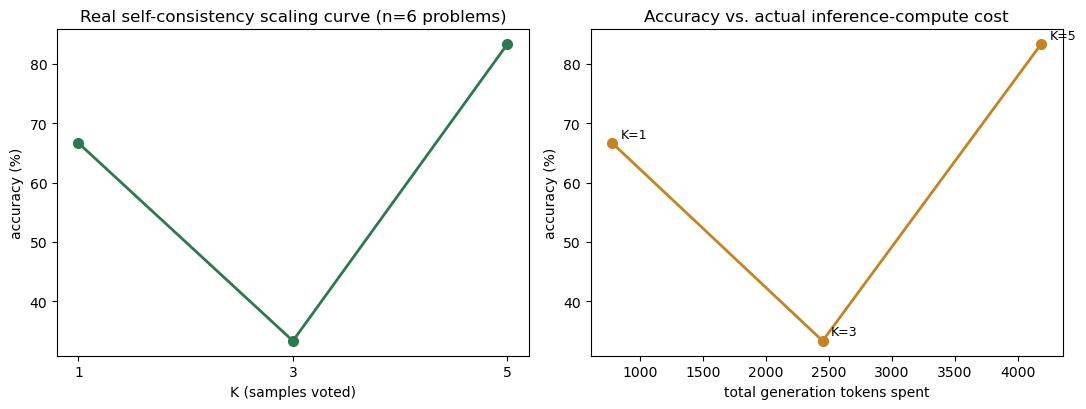

In [18]:
# Plot the K-vs-accuracy scaling curve (left) and the SAME data re-plotted against actual
# token cost instead of K (right) -- the point being that K itself isn't the real cost axis,
# tokens spent is, and the two don't have to scale identically.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(K_VALUES, [a*100 for a in accs], "o-", color="#2a7a4b", linewidth=2, markersize=7)
axes[0].set_xlabel("K (samples voted)"); axes[0].set_ylabel("accuracy (%)")
axes[0].set_title(f"Real self-consistency scaling curve (n={len(scaling_problems)} problems)")
axes[0].set_xticks(K_VALUES)

axes[1].plot(costs, [a*100 for a in accs], "o-", color="#C9821F", linewidth=2, markersize=7)
for k, c, a in zip(K_VALUES, costs, accs):
    axes[1].annotate(f"K={k}", (c, a*100), textcoords="offset points", xytext=(6, 4), fontsize=9)
axes[1].set_xlabel("total generation tokens spent"); axes[1].set_ylabel("accuracy (%)")
axes[1].set_title("Accuracy vs. actual inference-compute cost")
plt.tight_layout()
plt.savefig("part3_scaling_curve.png", dpi=150)
plt.show()

## 3.3 Self-reflection as compute allocation — same budget, spent differently

In [19]:
# Re-use the reflection MECHANISM from 2.5, but here measure it as a compute-allocation choice:
# K=5 parallel votes (3.2) vs. 1 initial attempt + 1 reflection-informed retry, on the SAME problem set.
# Both spend a similar order of magnitude of tokens -- the real question is which STRATEGY
# for spending that budget gets more accuracy per token: many independent parallel guesses
# (voting), or one attempt plus a targeted self-correction pass (reflection)?
def reflection_accuracy(problems):
    correct = 0
    total_tokens = 0
    for q, gold in problems:
        attempt1 = chat(f"{q}\nLet's think step by step.", max_new_tokens=150)
        total_tokens += len(tokenizer.encode(attempt1))
        pred1 = extract_number(attempt1)
        if pred1 == gold:
            correct += 1
            continue  # already correct -- no need to spend more tokens reflecting on this one
        # Only pay the extra reflection + retry cost on problems the first attempt got wrong.
        reflection = chat(f"Question: {q}\nYour answer: {attempt1}\nThe correct final number might differ -- briefly reconsider your arithmetic.", max_new_tokens=60)
        total_tokens += len(tokenizer.encode(reflection))
        attempt2 = chat(f"Question: {q}\nFirst attempt: {attempt1}\nReconsideration: {reflection}\nGive the corrected final number.", max_new_tokens=60)
        total_tokens += len(tokenizer.encode(attempt2))
        pred2 = extract_number(attempt2)
        correct += (pred2 == gold)
    return correct / len(problems), total_tokens

reflect_acc, reflect_tokens = reflection_accuracy(scaling_problems)
print(f"Reflection (1 attempt + informed retry on failures): accuracy={reflect_acc*100:.1f}%  tokens={reflect_tokens}")
print(f"Majority voting K=5 (from 3.2):                       accuracy={accs[-1]*100:.1f}%  tokens={costs[-1]}")
print("\nSame idea, two different ways to spend an inference budget -- Module 2 Part 3 SS02/S04's exact comparison table, with real numbers.")

Reflection (1 attempt + informed retry on failures): accuracy=66.7%  tokens=1199
Majority voting K=5 (from 3.2):                       accuracy=83.3%  tokens=4182

Same idea, two different ways to spend an inference budget -- Module 2 Part 3 SS02/S04's exact comparison table, with real numbers.


## 3.4 Putting it together — every approach from this Part, one chart

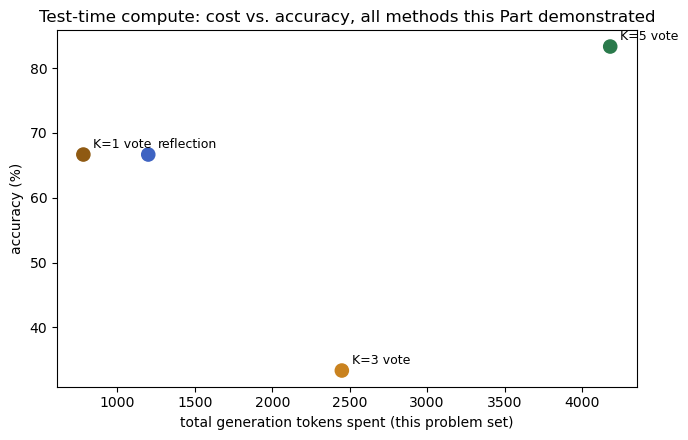

In [20]:
# Combine every Part-3 method (K=1/3/5 voting, plus reflection) onto one cost-vs-accuracy
# scatter plot -- the single chart that answers "given a fixed token budget, which
# test-time-compute strategy gets the best accuracy for that budget?"
labels = [f"K={k} vote" for k in K_VALUES] + ["reflection"]
all_accs = accs + [reflect_acc]
all_costs = costs + [reflect_tokens]

fig, ax = plt.subplots(figsize=(7, 4.5))
colors = ["#8F5A12", "#C9821F", "#2a7a4b", "#3E63C2"]
ax.scatter(all_costs, [a*100 for a in all_accs], s=90, c=colors)
for lbl, c, a in zip(labels, all_costs, all_accs):
    ax.annotate(lbl, (c, a*100), textcoords="offset points", xytext=(7, 5), fontsize=9)
ax.set_xlabel("total generation tokens spent (this problem set)")
ax.set_ylabel("accuracy (%)")
ax.set_title("Test-time compute: cost vs. accuracy, all methods this Part demonstrated")
plt.tight_layout()
plt.savefig("part3_all_methods.png", dpi=150)
plt.show()

---
# Part 4 — Structured Generation
*(companion: `4_Structured_Generation.html`)*

## 4.1 JSON Outputs — naive prompting vs. `outlines` constrained decoding

In [21]:
import outlines
from pydantic import BaseModel
from typing import Literal

# 5 sample product reviews we'll run through both the naive and constrained approaches below.
REVIEWS = [
    "The battery life is incredible but the camera is disappointing. Overall pretty good value.",
    "Absolutely terrible. Broke after two days and support never responded.",
    "It's fine. Does what it says, nothing more, nothing less.",
    "Best purchase this year! Fast shipping, great build quality, highly recommend.",
    "Mediocre at best. Overpriced for what you actually get.",
]

# Prompt template that just ASKS the model (in plain English) to output JSON with these
# exact keys -- nothing forces it to comply, it's pure instruction-following.
NAIVE_TEMPLATE = (
    'Analyze this product review and respond with ONLY a JSON object with exactly '
    'these keys: "sentiment" (positive/negative/neutral), "rating" (integer 1-5), '
    '"summary" (one short sentence). No other text.\n\nReview: "{review}"'
)

naive_hits = 0
for review in REVIEWS:
    # Generate free-text and try to parse it as JSON -- there's no guarantee it will be.
    raw = chat(NAIVE_TEMPLATE.format(review=review), max_new_tokens=120)
    try:
        parsed = json.loads(raw.strip())
        # Even if it parses, still need to check the required keys are actually present.
        ok = isinstance(parsed, dict) and {"sentiment", "rating", "summary"} <= parsed.keys()
    except json.JSONDecodeError:
        ok = False  # model didn't even produce valid JSON
    naive_hits += ok
    print(f"valid={ok!s:5}  raw={raw.strip()[:80]!r}")
naive_rate = naive_hits / len(REVIEWS)
print(f"\nNaive prompted-JSON success rate: {naive_rate*100:.0f}%")

valid=True   raw='{\n  "sentiment": "neutral",\n  "rating": 3,\n  "summary": "The reviewer finds the '


valid=False  raw='```json\n{\n  "sentiment": "negative",\n  "rating": 1,\n  "summary": "Product broke '


valid=False  raw='```json\n{\n  "sentiment": "neutral",\n  "rating": 4,\n  "summary": "The review is b'


valid=False  raw='```json\n{\n  "sentiment": "positive",\n  "rating": 4,\n  "summary": "This is the be'


valid=True   raw='{\n  "sentiment": "negative",\n  "rating": 2,\n  "summary": "The product is mediocr'

Naive prompted-JSON success rate: 40%


negative  rating=1  Battery life is great but camera performance is subpar overall. Not very good value for money.


negative  rating=1  The product is extremely bad - it broke within two days and the support has completely failed to respond.


neutral   rating=5  The review is brief but contains positive feedback on the product. The reviewer acknowledges that the product meets its stated purpose without going beyond expectations, which is generally considered a good sign. They use a straightforward and direct language to convey their satisfaction with the product. This type of review typically indicates a level of trust or confidence in the product's performance. The rating of 5 stars suggests that the review is likely to be well-received by potential buyers who value reliability and functionality. Overall, while not overly enthusiastic, the review conveys a sense of contentment with the product's performance.


positive  rating=5  This product is the best purchase of the year, with fast shipping and excellent build quality, making it highly recommended for anyone in need of an efficient and durable tool.


negative  rating=1  The product is mediocre at best and overpriced for the quality it offers.

Constrained-decoding success rate: 100% (5/5) -- by construction.


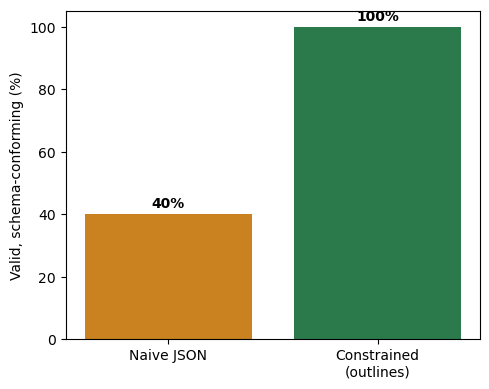

In [22]:
# NOTE: use Literal[1,2,3,4,5] rather than Field(ge=1,le=5) -- outlines' JSON-schema
# constraint compiles Literal/enum choices into the generation grammar reliably; a bare
# int with a numeric min/max is NOT always enforced at generation time by every backend,
# only validated after the fact -- exactly the kind of thing worth discovering by testing.
# This Pydantic model IS the schema that `outlines` will force the model's output to match.
class ReviewAnalysis(BaseModel):
    sentiment: Literal["positive", "negative", "neutral"]
    rating: Literal[1, 2, 3, 4, 5]
    summary: str

# Wrap the raw HF model + tokenizer so outlines can drive grammar-constrained generation.
outlines_model = outlines.from_transformers(hf_model, tokenizer)

constrained_results = []
for review in REVIEWS:
    messages = [{"role": "user", "content": f'Analyze this product review.\n\nReview: "{review}"'}]
    chat_prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    # Passing `ReviewAnalysis` here is what makes this "structured generation": outlines
    # compiles the schema into a grammar and only allows tokens that keep the output on a
    # valid path through that grammar -- invalid JSON/wrong types are impossible to produce.
    raw = outlines_model(chat_prompt, ReviewAnalysis, max_new_tokens=150)
    parsed = ReviewAnalysis.model_validate_json(raw)   # guaranteed to succeed now
    constrained_results.append(parsed)
    print(f"{parsed.sentiment:9s} rating={parsed.rating}  {parsed.summary}")

print(f"\nConstrained-decoding success rate: 100% ({len(constrained_results)}/{len(constrained_results)}) -- by construction.")

# Bar chart: naive prompting's parse success rate vs. constrained decoding's guaranteed 100%.
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["Naive JSON", "Constrained\n(outlines)"], [naive_rate*100, 100], color=["#C9821F", "#2a7a4b"])
ax.set_ylabel("Valid, schema-conforming (%)"); ax.set_ylim(0, 105)
for i, v in enumerate([naive_rate*100, 100]):
    ax.text(i, v+2, f"{v:.0f}%", ha="center", fontweight="bold")
plt.tight_layout(); plt.savefig("part4_json_reliability.png", dpi=150); plt.show()

## 4.2 Function / Tool Calling, formalized

Same lookup tool as Part 2.4's ReAct demo, but the model's *choice of tool + arguments* is now schema-constrained instead of hand-parsed from free text -- the structured-output plumbing underneath a real Action step.

In [23]:
# Schema for a structured "decision": which tool to call (or none) and with what argument.
# Same idea as ReviewAnalysis above, now used to formalize an agent's Action step.
class ToolCall(BaseModel):
    tool: Literal["lookup_fact", "no_tool_needed"]
    query: str

def decide_tool_call(question):
    # Ask the model whether it needs the tool -- but instead of parsing free text (like the
    # ReAct loop in Part 2.4 did with regex on "Action: lookup(...)"), the decision itself is
    # constrained to the ToolCall schema, so it's always machine-readable, never mis-parsed.
    messages = [{"role": "user", "content":
        f'You have one tool available: lookup_fact(query) -- looks up a fact.\n'
        f'Question: "{question}"\nDecide whether you need to call the tool, and with what query.'}]
    chat_prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    raw = outlines_model(chat_prompt, ToolCall, max_new_tokens=80)
    return ToolCall.model_validate_json(raw)

for q in ["How tall is Mount Everlore?", "What is 2 + 2?"]:
    decision = decide_tool_call(q)
    print(f"Q: {q}\n  -> structured decision: {decision}")
    # Only actually call the tool if the model decided it needed to.
    if decision.tool == "lookup_fact":
        print(f"  -> tool result: {lookup_tool(decision.query)}")
    print()

Q: How tall is Mount Everlore?
  -> structured decision: tool='lookup_fact' query='Mount Everlore'
  -> tool result: 8,850 meters tall, located in the fictional Kelvorian range



Q: What is 2 + 2?
  -> structured decision: tool='lookup_fact' query='What is 2 + 2?'
  -> tool result: No matching entry found.



## 4.3 LangChain — chain composition and a wrapped tool

Same local model, wrapped as a LangChain `ChatModel`. Demonstrates the `prompt | model | parser` chain pattern from the study guide, plus a `@tool`-decorated function -- the same reusable-infrastructure idea §04 describes, without depending on any specific model's native function-calling support (small local models like this one generally don't have it).

In [24]:
from transformers import pipeline as hf_pipeline
from langchain_huggingface import HuggingFacePipeline, ChatHuggingFace
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.tools import tool

# Wrap the same local HF model as a LangChain-compatible pipeline, then as a ChatModel, so
# it can be used inside LangChain's `prompt | model | parser` composition syntax (LCEL).
lc_pipe = hf_pipeline(
    "text-generation", model=hf_model, tokenizer=tokenizer,
    max_new_tokens=150, do_sample=False, return_full_text=False,
)
lc_llm = HuggingFacePipeline(pipeline=lc_pipe)
lc_chat = ChatHuggingFace(llm=lc_llm)

# --- A) plain chain: prompt | model | parser ---
# `|` pipes a prompt template into the chat model into an output parser. `.invoke(...)`
# fills the template's {text} placeholder, runs the model, and parses the raw output
# (here, just down to a plain string).
prompt = ChatPromptTemplate.from_template("Translate the following to French: {text}")
chain = prompt | lc_chat | StrOutputParser()
print("Chain output:", chain.invoke({"text": "good morning, how are you?"}))

# --- B) a LangChain tool, invoked manually after a structured decision ---
# `@tool` turns a plain function into a LangChain Tool object (with a name/description an
# LLM-facing agent could introspect), reusing the same lookup_tool from Part 2.4.
@tool
def lookup_fact(query: str) -> str:
    """Look up a fact from the local knowledge base."""
    return lookup_tool(query)

print("\nLangChain Tool object:", lookup_fact.name, "-", lookup_fact.description)
print("Direct invocation:", lookup_fact.invoke("zylarian crystal"))

[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


[transformers] The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


[transformers] Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Chain output: Bonjour, comment ça va ?

LangChain Tool object: lookup_fact - Look up a fact from the local knowledge base.
Direct invocation: melts at exactly -40 degrees Celsius


In [25]:
# --- C) chain + tool together: model decides via the chain, code executes the LangChain tool ---
# Unlike Part 4.2's outlines version, this decision is NOT schema-constrained -- it's still
# free text ("YES: <query>" / "NO") parsed by hand, same style as the original ReAct loop.
# This deliberately shows the "LangChain without outlines" version for comparison.
decision_prompt = ChatPromptTemplate.from_template(
    "Question: {question}\n"
    "Do you need to look up a fact to answer this? Reply with exactly 'YES: <query>' or 'NO'."
)
decision_chain = decision_prompt | lc_chat | StrOutputParser()

for q in ["How tall is Mount Everlore?", "What is the capital of Japan?"]:
    decision = decision_chain.invoke({"question": q}).strip()
    print(f"Q: {q}\n  decision: {decision}")
    if decision.upper().startswith("YES"):
        query = decision.split(":", 1)[-1].strip()
        result = lookup_fact.invoke(query)          # the actual LangChain Tool executes here
        print(f"  -> lookup_fact.invoke({query!r}) = {result!r}")
    print()

[transformers] Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Q: How tall is Mount Everlore?
  decision: NO



Q: What is the capital of Japan?
  decision: NO



## 4.4 DSPy — Prompt Optimization with `BootstrapFewShot`

In [26]:
import dspy

# DSPy needs an LM object with a specific `.forward()` contract (OpenAI-chat-shaped
# response). This class is pure plumbing: it takes DSPy's prompt/messages, runs them through
# the SAME local hf_model/tokenizer used everywhere else in this notebook, and repackages
# the output to look like an OpenAI chat-completion response so DSPy can consume it.
class LocalChatLM(dspy.BaseLM):
    """Wraps our local model as a DSPy-compatible LM (legacy/OpenAI-shaped forward contract)."""
    forward_contract = "legacy"

    def forward(self, prompt=None, messages=None, **kwargs):
        if messages is None:
            messages = [{"role": "user", "content": prompt}]
        chat_prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        inputs = tokenizer(chat_prompt, return_tensors="pt", truncation=True, max_length=2048).to(DEVICE)
        max_new = kwargs.get("max_tokens", self.kwargs.get("max_tokens") or 300)
        with torch.no_grad():
            out_ids = hf_model.generate(**inputs, max_new_tokens=max_new, do_sample=False, pad_token_id=tokenizer.eos_token_id)
        new_tokens = out_ids[0][inputs["input_ids"].shape[1]:]
        out_text = tokenizer.decode(new_tokens, skip_special_tokens=True)
        message = types.SimpleNamespace(role="assistant", content=out_text, tool_calls=None)
        choice = types.SimpleNamespace(index=0, message=message, finish_reason="stop", text=out_text)
        usage = {"prompt_tokens": int(inputs["input_ids"].shape[1]), "completion_tokens": int(new_tokens.shape[0]),
                  "total_tokens": int(inputs["input_ids"].shape[1] + new_tokens.shape[0])}
        return types.SimpleNamespace(id="local-0", object="chat.completion", created=int(time.time()),
                                      model=self.model, choices=[choice], usage=usage)

# Register this as DSPy's global LM -- every dspy.Predict / dspy.ChainOfThought call below
# routes through LocalChatLM.forward() under the hood.
lm = LocalChatLM(model=MODEL_NAME, model_type="chat", max_tokens=300)
dspy.configure(lm=lm)

# Reuse Part 3.2's arithmetic word problems and add two more -- a small labeled dataset.
dspy_problems = scaling_problems + [
    ("A parking lot has 7 rows with 12 cars in each row. How many cars in total?", "84"),
    ("Emma had 25 candies. She ate 4 and gave away 6. How many does she have left?", "15"),
]
random.shuffle(dspy_problems)
train_problems, dev_problems = dspy_problems[:6], dspy_problems[6:]

# dspy.Example is DSPy's data container: `question` is marked as the INPUT field via
# `.with_inputs("question")`; `answer` is the gold label, used only for scoring/training,
# never shown to the model verbatim at inference time.
trainset = [dspy.Example(question=q, answer=a).with_inputs("question") for q, a in train_problems]
devset = [dspy.Example(question=q, answer=a).with_inputs("question") for q, a in dev_problems]

# The metric DSPy uses to judge correctness: extract the numeric answer from both the
# model's prediction and the gold example, and compare them.
def exact_match_metric(example, prediction, trace=None):
    p, g = extract_number(str(prediction.answer)), extract_number(str(example.answer))
    return p is not None and g is not None and float(p) == float(g)

def evaluate_dspy(program, dataset, label):
    # `program(question=ex.question)` is the actual input -> output call: input `question`
    # goes in, a `Prediction` object with an `.answer` field comes out.
    correct = sum(exact_match_metric(ex, program(question=ex.question)) for ex in dataset)
    acc = correct / len(dataset)
    print(f"{label}: {correct}/{len(dataset)} = {acc*100:.1f}%")
    return acc

# `"question -> answer"` is a DSPy SIGNATURE -- it declares the input/output field names.
# dspy.ChainOfThought wraps that signature so the LM is prompted to reason step-by-step
# before producing the `answer` field. The actual prompt text is generated by DSPy, not
# hand-written here.
baseline_cot = dspy.ChainOfThought("question -> answer")
print("=== Baseline ==="); baseline_acc = evaluate_dspy(baseline_cot, devset, "baseline")

=== Baseline ===


baseline: 2/2 = 100.0%


  0%|          | 0/6 [00:00<?, ?it/s]

 17%|█▋        | 1/6 [00:07<00:36,  7.25s/it]

 33%|███▎      | 2/6 [00:15<00:31,  7.98s/it]

 50%|█████     | 3/6 [00:22<00:22,  7.63s/it]

 67%|██████▋   | 4/6 [16:56<13:13, 396.68s/it]

 67%|██████▋   | 4/6 [16:56<08:28, 254.02s/it]

Bootstrapped 3 full traces after 4 examples for up to 1 rounds, amounting to 4 attempts.
=== Compiled (BootstrapFewShot) ===


compiled: 2/2 = 100.0%


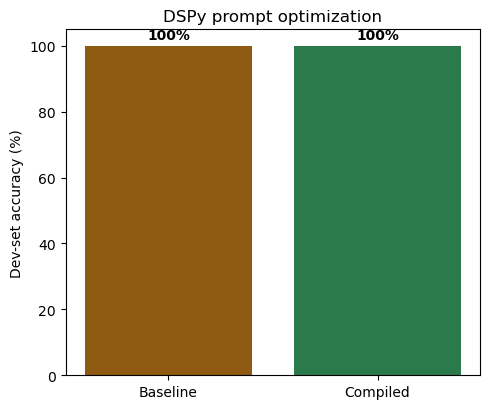

In [27]:
from dspy.teleprompt import BootstrapFewShot

# BootstrapFewShot is a DSPy OPTIMIZER ("teleprompter"): given the same signature and the
# trainset, it runs the program on training examples, keeps the ones that scored correctly
# under `exact_match_metric`, and inserts those runs as few-shot demonstrations in the prompt.
optimizer = BootstrapFewShot(metric=exact_match_metric, max_bootstrapped_demos=3, max_labeled_demos=3)
compiled_cot = optimizer.compile(dspy.ChainOfThought("question -> answer"), trainset=trainset)

print("=== Compiled (BootstrapFewShot) ===")
compiled_acc = evaluate_dspy(compiled_cot, devset, "compiled")

# Compare baseline (zero-shot CoT) vs. compiled (auto few-shot CoT) accuracy on the same devset.
fig, ax = plt.subplots(figsize=(5, 4.2))
ax.bar(["Baseline", "Compiled"], [baseline_acc*100, compiled_acc*100], color=["#8F5A12", "#2a7a4b"])
ax.set_ylabel("Dev-set accuracy (%)"); ax.set_ylim(0, 105)
ax.set_title("DSPy prompt optimization")
for i, v in enumerate([baseline_acc*100, compiled_acc*100]):
    ax.text(i, v+2, f"{v:.0f}%", ha="center", fontweight="bold")
plt.tight_layout(); plt.savefig("part4_dspy_optimization.png", dpi=150); plt.show()

In [28]:
# Prints the actual, fully-rendered prompt DSPy sent to the model on the last call --
# including the bootstrapped few-shot demos -- so you can see the real prompt text that
# was generated and optimized automatically, instead of hand-written by us.
dspy.inspect_history(n=1)





[2026-08-29T13:11:44.214701]

System message:

Your input fields are:
1. `question` (str):
Your output fields are:
1. `reasoning` (str): 
2. `answer` (str):
All interactions will be structured in the following way, with the appropriate values filled in.

[[ ## question ## ]]
{question}

[[ ## reasoning ## ]]
{reasoning}

[[ ## answer ## ]]
{answer}

[[ ## completed ## ]]
In adhering to this structure, your objective is: 
        Given the fields `question`, produce the fields `answer`.


User message:

[[ ## question ## ]]
A garden has 6 rows with 8 flowers in each row. How many flowers are there in total?


Assistant message:

[[ ## reasoning ## ]]
To find the total number of flowers in the garden, we multiply the number of rows by the number of flowers per row:

\[ \text{Total number of flowers} = (\text{Number of rows}) \times (\text{Number of flowers per row}) \]

\[ \text{Total number of flowers} = 6 \times 8 \]

\[ \text{Total number of flowers} = 48 \]

So,

\[ \text{Total n

## Summary — everything this notebook demonstrated

| # | Technique | Study guide | Section above |
|---|---|---|---|
| 1 | Zero-shot / few-shot prompting | Part 1 | 1.1 |
| 2 | Chain-of-thought | Part 1 | 1.3 |
| 3 | Self-consistency (majority vote) | Part 1 | 1.4 |
| 4 | Tree-of-Thoughts (generate/evaluate/prune) | Part 2 | 2.1 |
| 5 | Graph-of-Thoughts (aggregate branches) | Part 2 | 2.2 |
| 6 | Program-of-Thoughts / PAL (code execution) | Part 2 | 2.3 |
| 7 | **ReAct with real grounding** (ungrounded guess vs. tool-grounded answer) | Part 2 | 2.4 |
| 8 | Reflection (Reflexion-style retry) | Part 2 | 2.5 |
| 9 | Self-critique & verification | Part 2 | 2.6 |
| 10 | Deliberate reasoning (length dial) | Part 3 | 3.1 |
| 11 | Majority voting scaling curve (real data) | Part 3 | 3.2 |
| 12 | Reflection as compute allocation | Part 3 | 3.3 |
| 13 | JSON: naive vs. `outlines` constrained decoding | Part 4 | 4.1 |
| 14 | Function/tool calling (schema-constrained) | Part 4 | 4.2 |
| 15 | **LangChain** (chain composition + tool) | Part 4 | 4.3 |
| 16 | **DSPy** (`BootstrapFewShot` prompt optimization) | Part 4 | 4.4 |

Everything ran on one local `Qwen/Qwen2.5-0.5B-Instruct` model -- no API key, no cost per call.